# EDA global · Puntos de calor NASA FIRMS (MODIS + VIIRS)
**NASA Space Apps 2026** · Reto *Harmonization of MODIS and VIIRS Hot Spots*

Datos de **todos los países**: `data/db_nasa.duckdb` (389 M de detecciones, 2000–2025), abierta en modo solo lectura.
Las agregaciones se hacen dentro de DuckDB con `q("SELECT …")`, que devuelve un DataFrame.

In [116]:
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patheffects as pe
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.patches import Patch, Rectangle

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 120)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB = ROOT / "data" / "db_nasa.duckdb"
con = duckdb.connect(str(DB), read_only=True)


def q(sql, **params):
    """Corre SQL en DuckDB y devuelve un DataFrame. Parámetros con $nombre: q("... = $s", s="MODIS")."""
    return (con.execute(sql, params) if params else con.execute(sql)).df()


print(f"Conectado a {DB.relative_to(ROOT)} · {DB.stat().st_size / 1e9:.1f} GB")

Conectado a data/db_nasa.duckdb · 6.4 GB


### Estilo de gráficas
Un color fijo por sensor: **azul = MODIS**, **naranja = VIIRS S-NPP**, **aqua = VIIRS NOAA-20**. Para magnitudes se usa una rampa azul de un solo tono.

In [117]:
SURFACE, INK, INK2, MUTED, GRID, EJE = (
    "#fcfcfb",
    "#0b0b0b",
    "#52514e",
    "#898781",
    "#e1e0d9",
    "#c3c2b7",
)
GRIS = "#c9c7bf"  # "el resto" cuando se resalta un solo elemento

SENSORES = ["MODIS", "VIIRS_SNPP", "VIIRS_NOAA20"]
VIIRS = ["VIIRS_SNPP", "VIIRS_NOAA20"]
COLOR = {"MODIS": "#2a78d6", "VIIRS_SNPP": "#eb6834", "VIIRS_NOAA20": "#1baf7a"}
NOMBRE = {
    "MODIS": "MODIS (Terra + Aqua)",
    "VIIRS_SNPP": "VIIRS S-NPP",
    "VIIRS_NOAA20": "VIIRS NOAA-20",
}

AZUL = [
    "#cde2fb",
    "#b7d3f6",
    "#9ec5f4",
    "#86b6ef",
    "#6da7ec",
    "#5598e7",
    "#3987e5",
    "#2a78d6",
    "#256abf",
    "#1c5cab",
    "#184f95",
    "#104281",
    "#0d366b",
]
CMAP = LinearSegmentedColormap.from_list("azul", AZUL)
CMAP_MAPA = LinearSegmentedColormap.from_list(
    "azul_mapa", AZUL[3:]
)  # arranca más oscuro: 1 detección se ve
for c in (CMAP, CMAP_MAPA):
    c.set_bad(SURFACE)
MESES = [
    "Ene",
    "Feb",
    "Mar",
    "Abr",
    "May",
    "Jun",
    "Jul",
    "Ago",
    "Sep",
    "Oct",
    "Nov",
    "Dic",
]

plt.rcParams.update(
    {
        "figure.figsize": (11, 4),
        "figure.dpi": 110,
        "figure.constrained_layout.use": True,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "font.family": ["Arial", "DejaVu Sans"],
        "font.size": 10,
        "text.color": INK,
        "axes.edgecolor": EJE,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "grid.linestyle": "-",
        "axes.axisbelow": True,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK2,
        "axes.labelsize": 9.5,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelcolor": INK2,
        "ytick.labelcolor": INK2,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "lines.linewidth": 2,
        "lines.solid_capstyle": "round",
        "lines.solid_joinstyle": "round",
        "lines.markersize": 6,
        "lines.markeredgewidth": 1.5,
        "lines.markeredgecolor": SURFACE,
        "legend.frameon": False,
        "legend.fontsize": 9,
        "legend.labelcolor": INK2,
    }
)


def _comp(x, d, s):
    return f"{x / d:,.1f}".removesuffix(".0") + s


def compacto(x):
    """1234 -> '1,234' · 12900 -> '12.9K' · 4.2e6 -> '4.2M'."""
    a = abs(x)
    if a >= 1e9:
        return _comp(x, 1e9, "B")
    if a >= 1e6:
        return _comp(x, 1e6, "M")
    if a >= 1e4:
        return _comp(x, 1e3, "K")
    return f"{x:,.0f}"


def eje_numeros(ax, eje="y"):
    """Ticks limpios: completos bajo 10,000; compactos (10K, 2M) si el eje llega más arriba."""
    axis = ax.yaxis if eje == "y" else ax.xaxis
    tope = max(abs(v) for v in (ax.get_ylim() if eje == "y" else ax.get_xlim()))
    if tope >= 1e6:
        f = lambda x, _: _comp(x, 1e6, "M") if x else "0"
    elif tope >= 1e4:
        f = lambda x, _: _comp(x, 1e3, "K") if x else "0"
    else:
        f = lambda x, _: f"{x:,.0f}"
    axis.set_major_formatter(mticker.FuncFormatter(f))


def titulo(ax, texto, sub=None):
    """Título a la izquierda y, opcional, un subtítulo gris debajo."""
    ax.set_title(texto, pad=22 if sub else 10)
    if sub:
        ax.text(
            0, 1.015, sub, transform=ax.transAxes, color=INK2, fontsize=9.5, va="bottom"
        )


def leyenda_sensores(ax, sensores=SENSORES, **kw):
    handles = [plt.Line2D([], [], color=COLOR[s], lw=3) for s in sensores]
    ax.legend(handles, [NOMBRE[s] for s in sensores], **kw)


def etiqueta_final(ax, x, y, texto, dx=6, dy=0):
    ax.annotate(
        texto,
        (x, y),
        xytext=(dx, dy),
        textcoords="offset points",
        va="center",
        color=INK2,
        fontsize=9,
    )


def mapa_aspecto(ax, lat_media):
    ax.set_aspect(1 / np.cos(np.radians(lat_media)))
    ax.grid(False)
    ax.tick_params(labelsize=8)


def barra(fig, mappable, ax, label, **kw):
    """Colorbar con números normales (0.1, 1, 10, 100) en vez de potencias de 10."""
    cb = fig.colorbar(mappable, ax=ax, label=label, **kw)
    if isinstance(mappable.norm, LogNorm):
        cb.ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,g}"))
        cb.ax.yaxis.set_minor_formatter(mticker.NullFormatter())
    cb.outline.set_visible(False)
    return cb


def eje_log(ax, *ejes):
    """Ticks de un eje logarítmico como números normales: 1 · 10 · 100 · 1,000."""
    for e in ejes:
        (ax.xaxis if e == "x" else ax.yaxis).set_major_formatter(
            mticker.FuncFormatter(lambda x, _: f"{x:,g}")
        )


CONTORNO = [pe.withStroke(linewidth=3, foreground=SURFACE)]

---
## Datos globales
- `hotspots`: una fila por detección (todos los países, sensores y años).
- `resumen_mensual`: sensor × país × mes, precalculada (detecciones, detecciones de vegetación, FRP total).
- Vistas: `modis`, `viirs_snpp`, `viirs_noaa20`, `paises`.

In [118]:
display(
    q(
        "SELECT table_name AS tabla, table_type AS tipo FROM information_schema.tables ORDER BY 1"
    )
)
q("DESCRIBE hotspots")[["column_name", "column_type"]]

,tabla,tipo
0,_cargados,BASE TABLE
1,hotspots,BASE TABLE
2,modis,VIEW
3,paises,VIEW
4,resumen_mensual,BASE TABLE
5,viirs_noaa20,VIEW
6,viirs_snpp,VIEW


,column_name,column_type
0,sensor,VARCHAR
1,satellite,VARCHAR
2,country,VARCHAR
3,latitude,DOUBLE
4,longitude,DOUBLE
5,acq_date,DATE
6,acq_time,SMALLINT
7,confidence,VARCHAR
8,bright_mir,FLOAT
9,bright_tir,FLOAT


In [119]:
cobertura = (
    q("""
    SELECT sensor, min(acq_date) AS desde, max(acq_date) AS hasta,
           count(*) AS detecciones, count(DISTINCT country) AS paises
    FROM hotspots GROUP BY sensor
""")
    .set_index("sensor")
    .loc[SENSORES]
)
print(f"Total: {cobertura.detecciones.sum():,} detecciones")
cobertura

Total: 389,270,053 detecciones


,desde,hasta,detecciones,paises
sensor,,,,
MODIS,2000-11-01,2025-12-31,111424417,233
VIIRS_SNPP,2012-01-20,2017-12-31,121913364,234
VIIRS_NOAA20,2018-04-01,2025-12-31,155932272,234


In [120]:
fullbase = q("""
    SELECT *
    FROM hotspots
    USING SAMPLE 0.05% (bernoulli, 42)
""")
print(
    f"{len(fullbase):,} filas · {fullbase.country.nunique()} países · {fullbase.acq_date.nunique():,} fechas"
)
fullbase

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

195,051 filas · 183 países · 9,056 fechas


,sensor,satellite,country,latitude,longitude,acq_date,acq_time,confidence,bright_mir,bright_tir,scan,track,frp,daynight,type,version
0,MODIS,Terra,Cote d Ivoire,9.51810,-3.69590,2000-12-04,1044,89,340.500000,304.899994,1.60,1.20,71.099998,D,0,6.2
1,MODIS,Terra,Cote d Ivoire,8.68820,-7.12060,2000-12-11,1051,59,311.399994,297.200012,2.10,1.40,18.100000,D,0,6.2
2,MODIS,Terra,Cote d Ivoire,9.77120,-4.92770,2000-12-26,1146,49,321.600006,306.899994,4.00,1.90,54.799999,D,0,6.2
3,MODIS,Terra,Cote d Ivoire,9.84700,-7.06100,2000-12-30,1121,41,319.000000,305.600006,1.10,1.00,6.500000,D,0,6.2
4,MODIS,Terra,Argentina,-35.87370,-67.22650,2000-12-11,318,100,330.600006,295.799988,1.30,1.10,41.400002,N,0,6.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195046,VIIRS_SNPP,N,Zimbabwe,-17.13367,30.35056,2017-11-03,2253,n,300.160004,289.390015,0.56,0.43,1.340000,N,0,2
195047,VIIRS_SNPP,N,Zimbabwe,-18.51142,29.89727,2017-11-04,1124,l,343.570007,314.910004,0.46,0.39,5.380000,D,0,2
195048,VIIRS_SNPP,N,Zimbabwe,-20.52806,28.51524,2017-11-05,1105,n,354.019989,305.750000,0.37,0.58,6.470000,D,0,2
195049,VIIRS_SNPP,N,Zimbabwe,-18.60508,25.96735,2017-11-21,1105,h,367.000000,300.399994,0.52,0.67,49.419998,D,0,2


In [121]:
NOMBRE_SAT = {
    "Terra": "MODIS Terra",
    "Aqua": "MODIS Aqua",
    "N": "VIIRS S-NPP",
    "N20": "VIIRS NOAA-20",
}
COLOR_SAT = {"Terra": "#eda100", "Aqua": "#2a78d6", "N": "#eb6834", "N20": "#1baf7a"}


def grafica_por_satelite(por="año", solo_vegetacion=True):
    """Gráfica de líneas con las detecciones globales de cada satélite.

    por:             "año" o "mes"
    solo_vegetacion: True = solo type 0 (sin volcanes ni industria)
    Devuelve la tabla (periodo × satélite) con los conteos.
    """
    tiempo = "year(acq_date)" if por == "año" else "date_trunc('month', acq_date)"
    filtro = "WHERE type = 0" if solo_vegetacion else ""
    # por año, descarta años incompletos (Terra 2000, Aqua 2002, NOAA-20 2018)
    completos = "HAVING count(DISTINCT month(acq_date)) = 12" if por == "año" else ""
    datos = q(f"""
        SELECT satellite, {tiempo} AS periodo, count(*) AS detecciones
        FROM hotspots
        {filtro}
        GROUP BY satellite, periodo
        {completos}
        ORDER BY periodo
    """)
    tabla = datos.pivot(index="periodo", columns="satellite", values="detecciones")[
        list(NOMBRE_SAT)
    ]

    fig, ax = plt.subplots(figsize=(11, 4.2))
    for sat, nombre in NOMBRE_SAT.items():
        serie = tabla[sat].dropna()
        if por == "año":
            ax.plot(
                serie.index,
                serie.values,
                color=COLOR_SAT[sat],
                marker="o",
                markerfacecolor=COLOR_SAT[sat],
            )
            etiqueta_final(ax, serie.index[-1], serie.values[-1], nombre, dx=8)
        else:  # por mes las etiquetas finales chocan; basta la leyenda
            ax.plot(serie.index, serie.values, color=COLOR_SAT[sat], lw=1.3)
    if por == "año":
        ax.set_xlim(right=2029.5)  # espacio para las etiquetas
    ax.set_ylim(bottom=0)
    eje_numeros(ax)
    ax.set_ylabel(f"detecciones por {por}")
    ax.legend(
        [plt.Line2D([], [], color=COLOR_SAT[s], lw=3) for s in NOMBRE_SAT],
        NOMBRE_SAT.values(),
        loc="upper left",
    )
    titulo(
        ax,
        f"Detecciones de fuego por satélite, por {por} (todo el mundo)",
        ("Solo vegetación (type = 0)" if solo_vegetacion else "Todas las fuentes")
        + (" · años completos" if por == "año" else ""),
    )
    plt.show()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

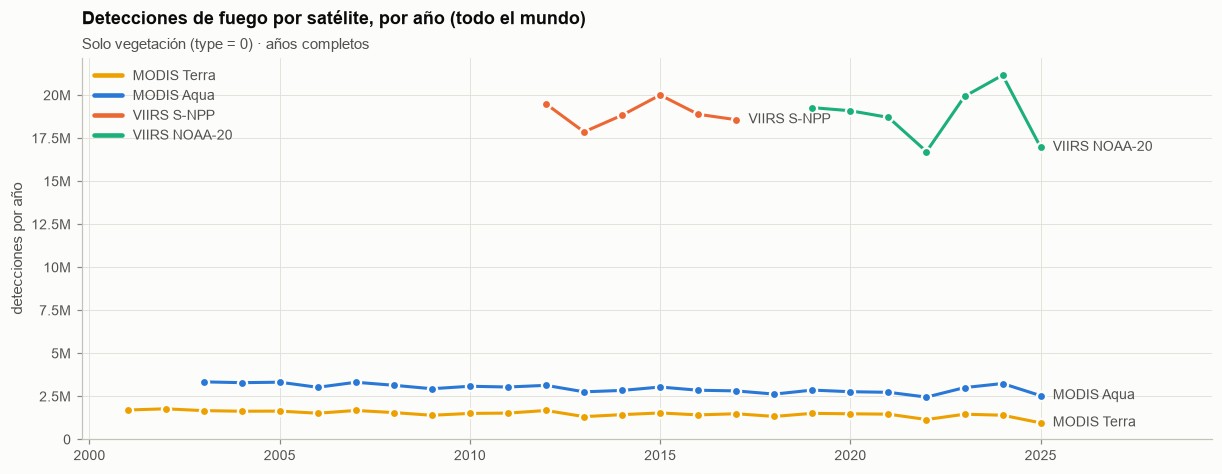

In [122]:
grafica_por_satelite()

In [123]:
def mapa_calor_satelites(solo_vegetacion=True):
    """¿El ciclo anual del fuego es el mismo en todos los satélites?

    Cada celda = % de las detecciones de ese satélite en ese año que cayó en ese mes
    (cada satélite-año suma 100 %). Así se quita la diferencia de nivel entre satélites
    y todos comparten una sola escala de color.

    Filas = meses. Columnas = años; dentro de cada año, posiciones fijas:
    T = Terra · A = Aqua · V = VIIRS (S-NPP hasta 2017, NOAA-20 desde 2019).
    Al final, el promedio de todos los años con los % escritos.
    Solo años completos (12 meses) de cada satélite.
    Devuelve la tabla (satélite, año, mes, detecciones, pct).
    """
    from matplotlib.cm import ScalarMappable
    from matplotlib.colors import TwoSlopeNorm

    datos = q(f"""
        SELECT satellite, year(acq_date) AS anio, month(acq_date) AS mes, count(*) AS detecciones
        FROM hotspots
        {"WHERE type = 0" if solo_vegetacion else ""}
        GROUP BY ALL
    """)
    datos["pos"] = datos.satellite.map(
        {"Terra": "T", "Aqua": "A", "N": "V", "N20": "V"}
    )
    completos = datos.groupby(["satellite", "anio"]).mes.transform("nunique") == 12
    datos = datos[completos].copy()
    datos["pct"] = (
        datos.detecciones
        / datos.groupby(["satellite", "anio"]).detecciones.transform("sum")
        * 100
    )
    datos = datos.sort_values(["anio", "pos", "mes"]).reset_index(drop=True)

    POSICIONES = ["T", "A", "V"]
    TIPICO = 100 / 12  # si el fuego se repartiera parejo, cada mes tendría 8.3 %
    # Divergente: rojo = más fuego que un mes típico, azul = menos, gris = lo normal
    cmap = LinearSegmentedColormap.from_list(
        "mes_tipico", ["#184f95", "#6da7ec", "#f0efec", "#ec8a89", "#b8302f"]
    )
    norm = TwoSlopeNorm(vcenter=TIPICO, vmin=datos.pct.min(), vmax=datos.pct.max())
    HUECO = 0.5

    fig, ax = plt.subplots(figsize=(14, 6.6))
    x, centros, etiquetas = 0.0, [], []
    for anio in sorted(datos.anio.unique()):
        x0 = x
        for pos in POSICIONES:
            d = datos[(datos.pos == pos) & (datos.anio == anio)]
            if not d.empty:
                valores = d.set_index("mes").pct.reindex(range(1, 13)).values
                ax.imshow(
                    cmap(norm(valores))[:, None, :],
                    extent=(x + 0.05, x + 0.95, 12.5, 0.5),
                    aspect="auto",
                    interpolation="nearest",
                )
            ax.text(
                x + 0.5, 0.35, pos, ha="center", va="bottom", fontsize=6.5, color=MUTED
            )
            x += 1
        centros.append((x0 + x) / 2)
        etiquetas.append(str(anio))
        x += HUECO

    # Bloque final: promedio de todos los años, con los % escritos
    x += 1.0
    x0, ancho = x, 1.7
    prom = datos.groupby(["pos", "mes"]).pct.mean().unstack(0)[POSICIONES]
    for pos in POSICIONES:
        valores = prom[pos].values
        ax.imshow(
            cmap(norm(valores))[:, None, :],
            extent=(x + 0.05, x + ancho - 0.05, 12.5, 0.5),
            aspect="auto",
            interpolation="nearest",
        )
        for mes, v in enumerate(valores, 1):
            ax.text(
                x + ancho / 2,
                mes,
                f"{v:.0f}%",
                ha="center",
                va="center",
                fontsize=7.5,
                color="white" if abs(norm(v) - 0.5) > 0.3 else INK,
            )
        ax.text(
            x + ancho / 2,
            0.35,
            pos,
            ha="center",
            va="bottom",
            fontsize=6.5,
            color=MUTED,
        )
        x += ancho
    centros.append((x0 + x) / 2)
    etiquetas.append("Promedio")

    ax.set_xlim(-HUECO, x + 0.2)
    ax.set_ylim(12.5, -0.3)
    ax.set_yticks(range(1, 13), MESES, fontsize=9)
    ax.set_xticks(centros, etiquetas, fontsize=8, rotation=90)
    ax.get_xticklabels()[-1].set_fontweight("bold")
    ax.tick_params(length=0)
    ax.grid(False)
    for lado in ("top", "right", "bottom", "left"):
        ax.spines[lado].set_visible(False)

    cb = fig.colorbar(
        ScalarMappable(norm=norm, cmap=cmap),
        ax=ax,
        orientation="horizontal",
        shrink=0.45,
        pad=0.02,
        aspect=35,
        label="% de las detecciones del año en ese mes · rojo = más fuego que un mes típico, azul = menos",
    )
    marcas = sorted(
        [
            v
            for v in range(2, int(datos.pct.max()) + 1, 2)
            if norm.vmin <= v <= norm.vmax and abs(v - TIPICO) > 1
        ]
        + [TIPICO]
    )
    cb.set_ticks(marcas)
    cb.ax.xaxis.set_major_formatter(
        mticker.FuncFormatter(
            lambda v, _: "8.3%\nmes típico" if abs(v - TIPICO) < 0.01 else f"{v:.0f}%"
        )
    )
    cb.ax.tick_params(labelsize=8)
    cb.outline.set_visible(False)

    titulo(
        ax,
        "El ciclo anual del fuego es el mismo en todos los satélites",
        "En cada año: T = Terra · A = Aqua · V = VIIRS (S-NPP 2012–17, NOAA-20 2019–25)"
        " · en blanco: el satélite no operaba o el año está incompleto"
        + (" · solo vegetación" if solo_vegetacion else ""),
    )
    plt.show()
    return datos

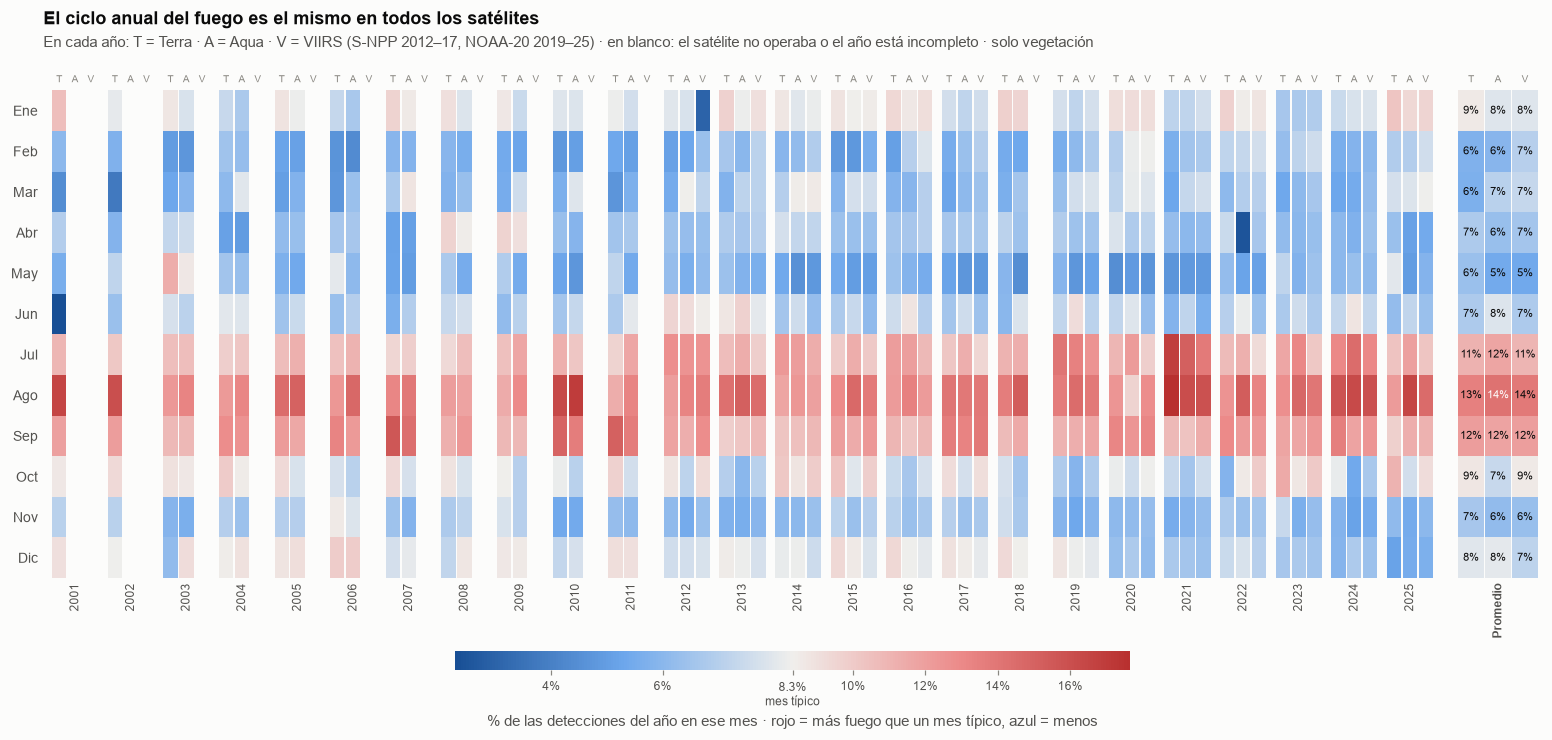

,satellite,anio,mes,detecciones,pos,pct
0,Terra,2001,1,179955,T,10.539450
1,Terra,2001,2,103244,T,6.046706
2,Terra,2001,3,75844,T,4.441966
3,Terra,2001,4,118454,T,6.937512
4,Terra,2001,5,95754,T,5.608038
...,...,...,...,...,...,...
727,N20,2025,8,2465120,V,14.522452
728,N20,2025,9,1895027,V,11.163935
729,N20,2025,10,1560991,V,9.196070
730,N20,2025,11,1026035,V,6.044551


In [124]:
mapa_calor_satelites()

In [ ]:
def cajas(ax, grupos, posiciones, color, ancho=0.6, horizontal=False):
    """Diagrama de caja y bigotes: caja = 50 % central de los valores, línea blanca = mediana,
    bigotes = rango normal (hasta 1.5 veces el alto de la caja), puntos = valores atípicos."""
    ax.boxplot(
        grupos,
        positions=posiciones,
        widths=ancho,
        patch_artist=True,
        manage_ticks=False,
        orientation="horizontal" if horizontal else "vertical",
        boxprops=dict(facecolor=color, edgecolor=color),
        medianprops=dict(color=SURFACE, lw=2),
        whiskerprops=dict(color=color, lw=1.5),
        capprops=dict(color=color, lw=1.5),
        flierprops=dict(
            marker="o",
            markersize=3,
            markerfacecolor=color,
            markeredgecolor="none",
            alpha=0.4,
        ),
    )


def conteo_por_satelite(desde="2012-01-20", solo_vegetacion=False):
    """¿Cuántos puntos de calor detecta cada satélite por día, y cuánto varía de un día a otro?

    Cada satélite operó en años distintos, así que el total no es comparable.
    Se compara el promedio de detecciones por día con datos, desde la misma fecha para todos
    (por defecto desde que existe VIIRS: 20-ene-2012).
    """
    diario = q(f"""
        SELECT satellite, acq_date, count(*) AS detecciones
        FROM hotspots
        WHERE acq_date >= DATE '{desde}' {"AND type = 0" if solo_vegetacion else ""}
        GROUP BY ALL
    """)
    g = diario.groupby("satellite").detecciones
    datos = pd.DataFrame(
        {
            "desde": diario.groupby("satellite").acq_date.min(),
            "hasta": diario.groupby("satellite").acq_date.max(),
            "dias": g.size(),
            "detecciones": g.sum(),
            "por_dia": g.mean(),
            "p25": g.quantile(0.25),
            "mediana": g.median(),
            "p75": g.quantile(0.75),
        }
    ).loc[list(NOMBRE_SAT)]
    datos["veces_terra"] = datos.por_dia / datos.por_dia["Terra"]
    datos["veces_aqua"] = datos.por_dia / datos.por_dia["Aqua"]

    fig, (ax, ax2) = plt.subplots(
        1, 2, figsize=(14, 3.9), sharey=True, width_ratios=[1.15, 1]
    )
    y = np.arange(len(datos))[::-1]

    # Izquierda: promedio por día
    ax.barh(y, datos.por_dia, color=[COLOR_SAT[s] for s in datos.index], height=0.6)
    for yi, (s, f) in zip(y, datos.iterrows()):
        ax.text(
            f.por_dia + datos.por_dia.max() * 0.01,
            yi,
            f"  {compacto(f.por_dia)} · "
            + ("referencia" if s == "Terra" else f"{f.veces_terra:.1f}× Terra"),
            va="center",
            fontsize=10,
            color=INK,
        )
    ax.set_yticks(y, [NOMBRE_SAT[s] for s in datos.index])
    ax.tick_params(axis="y", length=0)
    ax.set_xlim(0, datos.por_dia.max() * 1.45)
    eje_numeros(ax, "x")
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("detecciones promedio por día")
    titulo(
        ax,
        "Promedio por día",
        f"Global desde {desde} · "
        + (
            "solo vegetación"
            if solo_vegetacion
            else "todos los tipos (vegetación, volcanes, industria, mar)"
        ),
    )

    # Derecha: dispersión día a día
    for yi, s in zip(y, datos.index):
        cajas(
            ax2,
            [diario.detecciones[diario.satellite == s]],
            [yi],
            COLOR_SAT[s],
            horizontal=True,
        )
    ax2.set_xlim(left=0)
    eje_numeros(ax2, "x")
    ax2.grid(axis="y", visible=False)
    ax2.tick_params(axis="y", length=0)
    ax2.set_xlabel("detecciones en un día")
    titulo(
        ax2,
        "¿Cuánto varía de un día a otro?",
        "Caja = 50 % central de los días · línea blanca = mediana · puntos = días atípicos",
    )

    viirs = datos[datos.index.isin(["N", "N20"])]
    fig.suptitle(
        f"VIIRS detecta ~{viirs.veces_terra.mean():.0f} veces más puntos que MODIS Terra "
        f"y ~{viirs.veces_aqua.mean():.0f} veces más que Aqua",
        x=0.01,
        ha="left",
        fontweight="bold",
        fontsize=13,
    )
    plt.show()

    return datos.rename(
        columns={
            "por_dia": "promedio por día",
            "veces_terra": "veces Terra",
            "veces_aqua": "veces Aqua",
        }
    ).round(
        {
            "promedio por día": 0,
            "p25": 0,
            "mediana": 0,
            "p75": 0,
            "veces Terra": 1,
            "veces Aqua": 1,
        }
    )

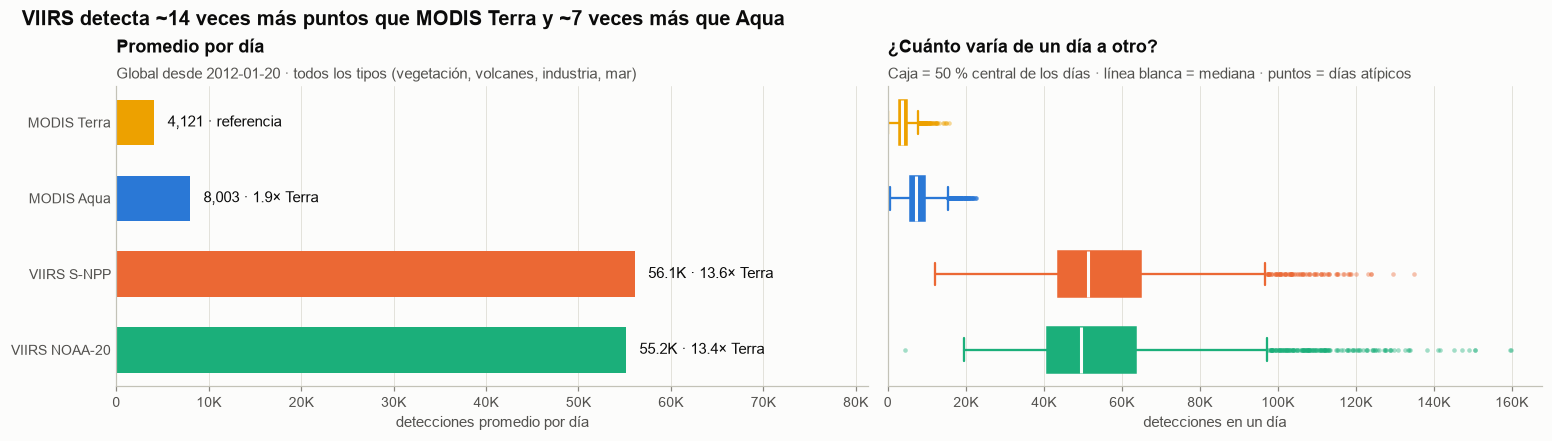

,desde,hasta,dias,detecciones,promedio por día,p25,mediana,p75,veces Terra,veces Aqua
satellite,,,,,,,,,,
Terra,2012-01-20,2025-12-31,5074,20911048,4121.0,2941.0,3723.0,4912.0,1.0,0.5
Aqua,2012-01-20,2025-12-31,5079,40648658,8003.0,5605.0,7159.0,9561.0,1.9,1.0
N,2012-01-20,2017-12-31,2172,121913364,56130.0,43602.0,51459.0,65013.0,13.6,7.0
N20,2018-04-01,2025-12-31,2826,155932272,55178.0,40874.0,49432.0,63528.0,13.4,6.9


In [126]:
conteo_por_satelite()

In [ ]:
def promedio_mensual(referencia="Aqua", desde="2012-01-01", solo_vegetacion=False):
    """Detecciones promedio por mes en un satélite y cuántas veces más (o menos) detectan los otros.
    Después, lo mismo en cajas y bigotes para ver cuánto cambia de un año a otro.

    referencia:      "Terra", "Aqua", "N" (S-NPP) o "N20" (NOAA-20)
    desde:           solo usa meses desde esta fecha (2012 = ya existía VIIRS)
    solo_vegetacion: False = todos los tipos de detección
    Solo cuenta meses completos (sin días sin datos), para comparar parejo.
    """
    datos = q(f"""
        SELECT satellite, year(acq_date) AS año, month(acq_date) AS mes,
               count(*) AS detecciones, count(DISTINCT acq_date) AS dias
        FROM hotspots
        WHERE acq_date >= DATE '{desde}' {"AND type = 0" if solo_vegetacion else ""}
        GROUP BY ALL
    """)
    dias_del_mes = pd.to_datetime(
        dict(year=datos.año, month=datos.mes, day=1)
    ).dt.days_in_month
    datos = datos[datos.dias == dias_del_mes]
    tabla = datos.pivot(index=["año", "mes"], columns="satellite", values="detecciones")

    # 1) promedio de cada mes del año, por satélite
    promedio = tabla.groupby(level="mes").mean().reindex(columns=list(NOMBRE_SAT))
    # 2) cuántas veces la referencia: solo meses (mismo mes y año) en que ambos tienen datos
    otros = [
        s
        for s in NOMBRE_SAT
        if s != referencia and not tabla[[referencia, s]].dropna().empty
    ]
    razon, veces, veces_total = {}, {}, {}
    for s in otros:
        par = tabla[[referencia, s]].dropna()
        razon[s] = par[s] / par[referencia]  # un valor por mes-año
        suma = par.groupby(level="mes").sum()
        veces[s] = suma[s] / suma[referencia]
        veces_total[s] = par[s].sum() / par[referencia].sum()
    veces = pd.DataFrame(veces)

    x = np.arange(1, 13)
    ancho = 0.8 / len(otros)
    posicion = {s: x - 0.4 + ancho * (k + 0.5) for k, s in enumerate(otros)}
    años = tabla[referencia].dropna().index.get_level_values("año")
    alcance = f"{años.min()}–{años.max()} · global · " + (
        "solo vegetación" if solo_vegetacion else "todos los tipos"
    )
    linea_ref = plt.Line2D([], [], color=INK2, lw=1)

    def ejes_comunes(ax_arriba, ax_abajo):
        eje_numeros(ax_arriba, "y")
        ax_arriba.grid(axis="x", visible=False)
        ax_arriba.tick_params(labelbottom=True)
        ax_abajo.axhline(1, color=INK2, lw=1)
        ax_abajo.yaxis.set_major_formatter(
            mticker.FuncFormatter(lambda v, _: f"{v:g}×")
        )
        ax_abajo.grid(axis="x", visible=False)
        ax_abajo.set_xticks(x, MESES)

    # ── Figura 1: barras con el promedio ──
    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(12, 8.5), sharex=True, height_ratios=[1, 1.2]
    )
    ref = promedio[referencia]
    ax1.bar(x, ref, width=0.7, color=COLOR_SAT[referencia])
    for m, v in ref.items():
        ax1.text(m, v, compacto(v), ha="center", va="bottom", fontsize=9, color=INK2)
    ax1.set_ylim(0, ref.max() * 1.15)
    titulo(
        ax1,
        f"{NOMBRE_SAT[referencia]}: detecciones promedio por mes",
        f"Promedio de cada mes, {alcance}",
    )
    for s in otros:
        ax2.bar(
            posicion[s],
            veces[s],
            width=ancho,
            color=COLOR_SAT[s],
            edgecolor=SURFACE,
            linewidth=1,
        )
    ax2.set_ylim(0, veces.max().max() * 1.2)
    ax2.legend(
        [linea_ref] + [Patch(color=COLOR_SAT[s]) for s in otros],
        [f"{NOMBRE_SAT[referencia]} = 1×"]
        + [f"{NOMBRE_SAT[s]} · {veces_total[s]:.1f}× en promedio" for s in otros],
        loc="upper left",
        ncol=len(otros) + 1,
        frameon=False,
    )
    titulo(
        ax2,
        f"Los otros satélites: ¿cuántas veces lo que detecta {NOMBRE_SAT[referencia]}?",
        "Comparando el mismo mes del mismo año · línea = igual que la referencia",
    )
    ejes_comunes(ax1, ax2)
    plt.show()

    # ── Figura 2: cajas y bigotes, cada año es un valor ──
    fig, (ax3, ax4) = plt.subplots(
        2, 1, figsize=(12, 8.5), sharex=True, height_ratios=[1, 1.2]
    )
    por_mes = tabla[referencia].dropna().groupby(level="mes")
    cajas(
        ax3,
        [g.to_numpy() for _, g in por_mes],
        [m for m, _ in por_mes],
        COLOR_SAT[referencia],
        ancho=0.6,
    )
    ax3.set_ylim(bottom=0)
    titulo(
        ax3,
        f"{NOMBRE_SAT[referencia]}: ¿cuánto cambia cada mes de un año a otro?",
        f"Cada año es un valor ({alcance}) · caja = 50 % central · línea blanca = mediana · puntos = años atípicos",
    )
    for s in otros:
        por_mes = razon[s].groupby(level="mes")
        cajas(
            ax4,
            [g.to_numpy() for _, g in por_mes],
            posicion[s][[m - 1 for m, _ in por_mes]],
            COLOR_SAT[s],
            ancho=ancho * 0.85,
        )
    ax4.set_ylim(0, max(r.max() for r in razon.values()) * 1.15)
    ax4.legend(
        [linea_ref] + [Patch(color=COLOR_SAT[s]) for s in otros],
        [f"{NOMBRE_SAT[referencia]} = 1×"] + [NOMBRE_SAT[s] for s in otros],
        loc="upper left",
        ncol=len(otros) + 1,
        frameon=False,
    )
    titulo(
        ax4,
        f"Los otros satélites en veces {NOMBRE_SAT[referencia]}: ¿la diferencia es estable de un año a otro?",
        "Cada caja junta el mismo mes de todos los años en que ambos satélites tienen datos",
    )
    ejes_comunes(ax3, ax4)
    plt.show()

    resultado = pd.concat(
        {
            "promedio por mes": promedio.round(0),
            f"veces {NOMBRE_SAT[referencia]}": veces.round(2),
        },
        axis=1,
    )
    resultado = resultado.rename(columns=NOMBRE_SAT, level=1)
    resultado.index = MESES
    return resultado

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

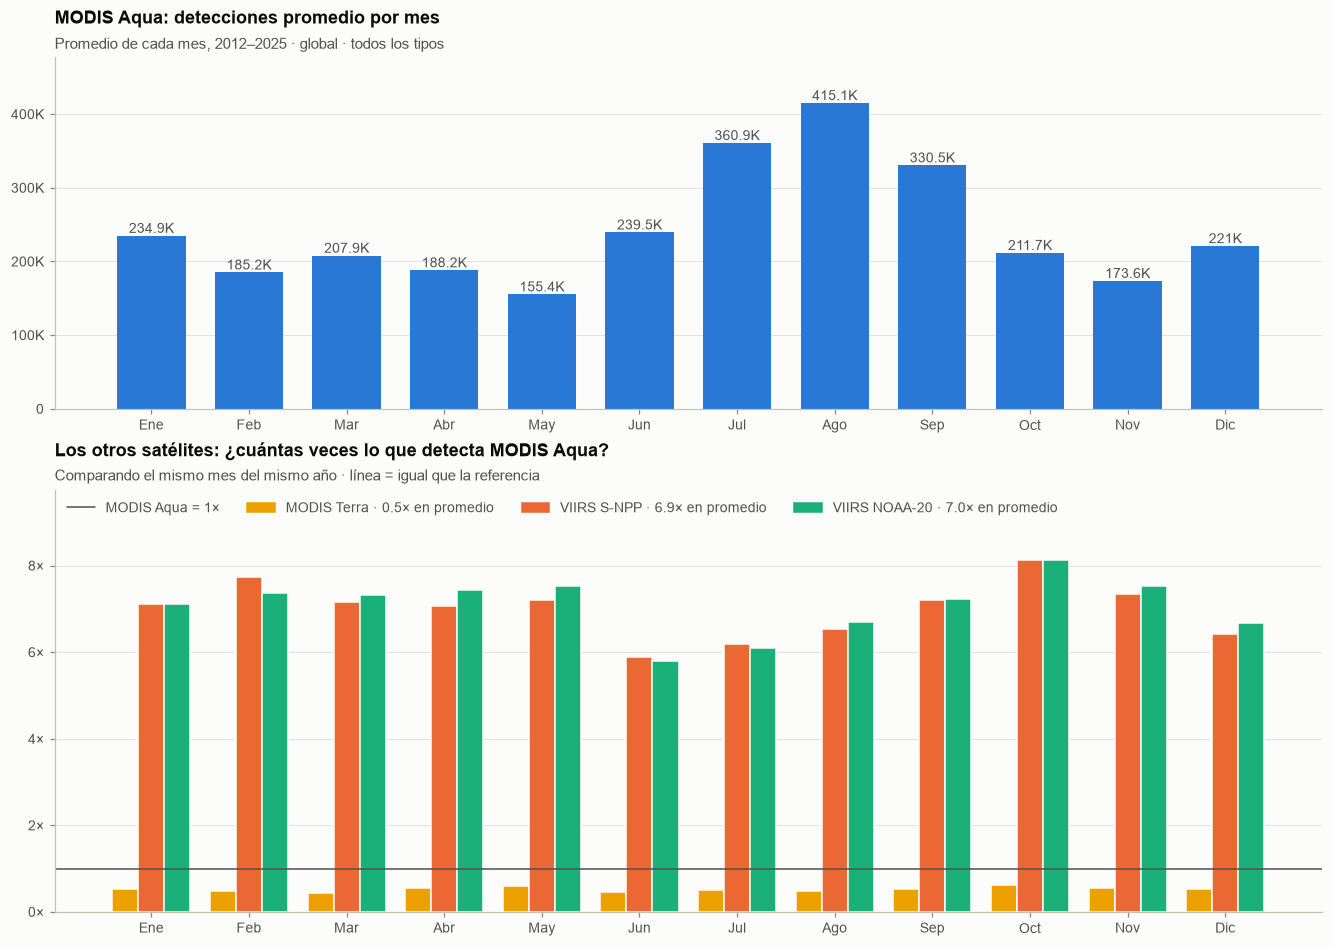

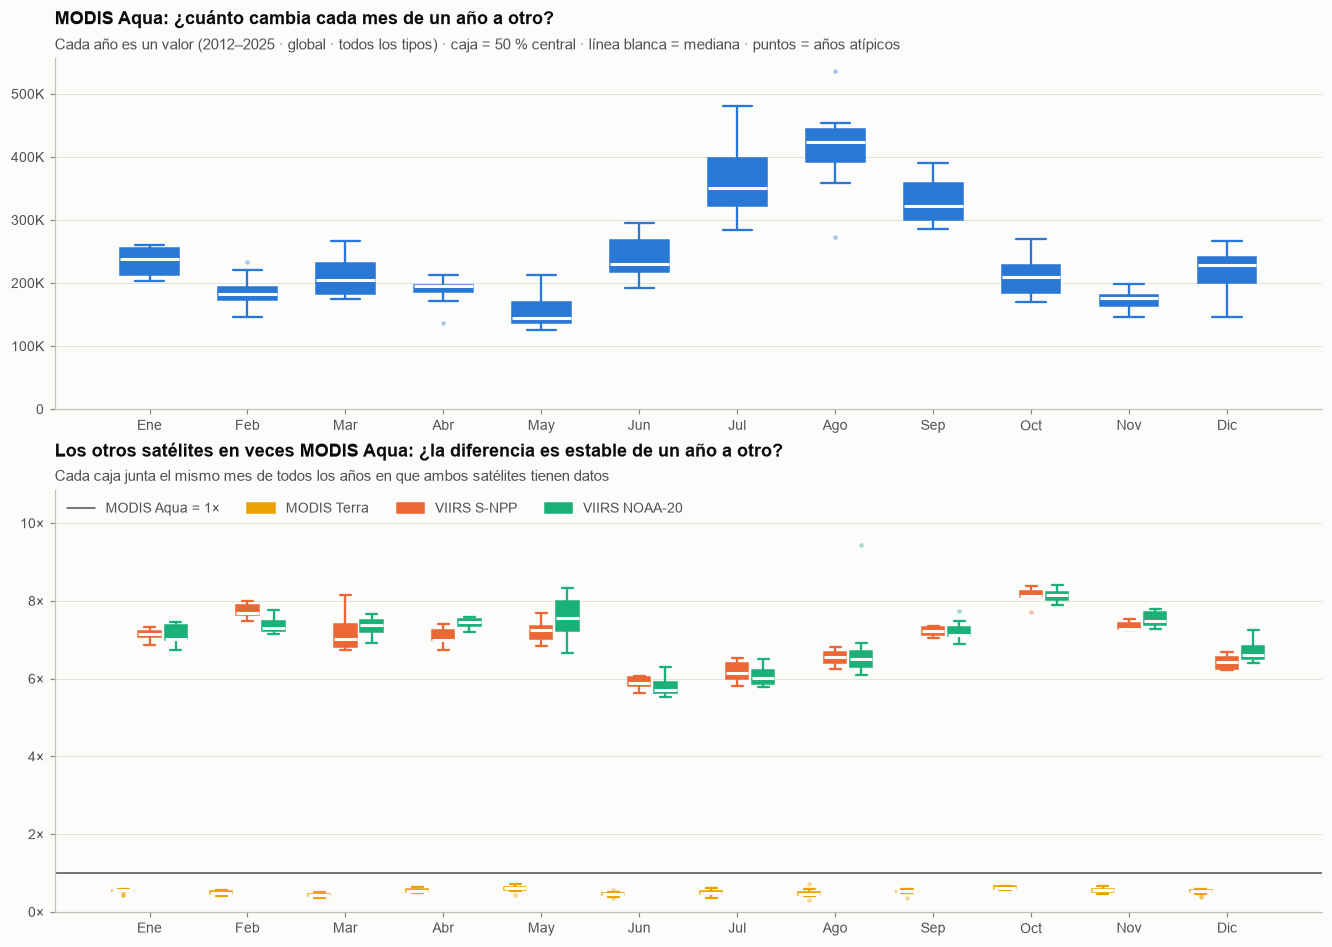

promedio por mes                                      veces MODIS Aqua                          
         MODIS Terra MODIS Aqua VIIRS S-NPP VIIRS NOAA-20      MODIS Terra VIIRS S-NPP VIIRS NOAA-20
Ene         125496.0   234907.0   1685060.0     1626744.0             0.53        7.12          7.12
Feb          89016.0   185195.0   1370649.0     1455340.0             0.48        7.73          7.36
Mar          91000.0   207888.0   1488854.0     1488811.0             0.44        7.17          7.32
Abr         102896.0   188182.0   1403304.0     1318637.0             0.55        7.07          7.43
May          92167.0   155395.0   1147183.0     1148527.0             0.59        7.21          7.52
Jun         109721.0   239534.0   1469305.0     1345113.0             0.46        5.88          5.80
Jul         178252.0   360868.0   2166122.0     2220551.0             0.49        6.19          6.10
Ago         199026.0   415120.0   2667968.0     2820146.0             0.48        6.54          6.70
Sep         172612.0   330534.0   2391802.0     2352998.0             0.52        7.21          7.23
Oct         132302.0   211736.0   1798159.0     1660808.0             0.63        8.12          8.12
Nov          97282.0   173647.0   1331696.0     1263660.0             0.56        7.35          7.52
Dic         115601.0   220972.0   1573890.0     1354300.0             0.52        6.42          6.67

In [128]:
promedio_mensual()